In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
!unzip /content/archive.zip


Streaming output truncated to the last 5000 lines.
  inflating: train_another/no_damage/-95.627453_29.859303000000004.jpeg  
  inflating: train_another/no_damage/-95.62745600000001_29.777524.jpeg  
  inflating: train_another/no_damage/-95.627485_29.777865999999996.jpeg  
  inflating: train_another/no_damage/-95.62751800000001_29.857785999999997.jpeg  
  inflating: train_another/no_damage/-95.62751999999999_29.860796999999998.jpeg  
  inflating: train_another/no_damage/-95.627523_29.770004999999998.jpeg  
  inflating: train_another/no_damage/-95.62753000000001_29.863289.jpeg  
  inflating: train_another/no_damage/-95.627539_29.827047999999998.jpeg  
  inflating: train_another/no_damage/-95.627543_29.860021000000003.jpeg  
  inflating: train_another/no_damage/-95.627563_29.8628.jpeg  
  inflating: train_another/no_damage/-95.627579_29.864051.jpeg  
  inflating: train_another/no_damage/-95.627595_29.776602.jpeg  
  inflating: train_another/no_damage/-95.62759799999999_29.777317.jpeg  
  i

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("TensorFlow Version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
TRAIN_DIR = "/content/test_another"
VAL_DIR   = "/content/validation_another"
TEST_DIR  = "/content/test"

IMG_SIZE = 224
BATCH_SIZE = 32

In [4]:
train_datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2]
)

val_datagen = ImageDataGenerator()

test_datagen = ImageDataGenerator()

In [5]:
train_data = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=True
)

val_data = val_datagen.flow_from_directory(
    VAL_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

test_data = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print("Class mapping:", train_data.class_indices)

Found 9000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.
Class mapping: {'damage': 0, 'no_damage': 1}


In [6]:
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [7]:
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(
    256,
    activation="relu"
)(x)

x = Dropout(0.4)(x)

x = Dense(
    128,
    activation="relu"
)(x)

x = Dropout(0.3)(x)

output = Dense(
    1,
    activation="sigmoid"
)(x)

model = Model(
    inputs=base_model.input,
    outputs=output
)

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,410,532 (16.82 MB)

 Trainable params: 360,961 (1.38 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [9]:
checkpoint = ModelCheckpoint(
    "/content/working_pp/best_building_damage_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

In [12]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)

Epoch 1/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.9616 - auc: 0.9747 - loss: 0.1109 - precision: 0.8676 - recall: 0.7693
Epoch 1: val_accuracy did not improve from 0.79100
282/282 ━━━━━━━━━━━━━━━━━━━━ 128s 455ms/step - accuracy: 0.9600 - auc: 0.9717 - loss: 0.1144 - precision: 0.8730 - recall: 0.7490 - val_accuracy: 0.7605 - val_auc: 0.9756 - val_loss: 0.5740 - val_precision: 0.9924 - val_recall: 0.5250 - learning_rate: 1.2500e-05
Epoch 2/20
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step - accuracy: 0.9644 - auc: 0.9775 - loss: 0.1061 - precision: 0.9127 - recall: 0.7470
Epoch 2: val_accuracy did not improve from 0.79100

Epoch 2: ReduceLROnPlateau reducing learning rate to 6.24999984211172e-06.
282/282 ━━━━━━━━━━━━━━━━━━━━ 131s 463ms/step - accuracy: 0.9628 - auc: 0.9789 - loss: 0.1058 - precision: 0.8973 - recall: 0.7510 - val_accuracy: 0.7725 - val_auc: 0.9755 - val_loss: 0.5568 - val_precision: 0.9928 - val_recall: 0.5490 - learning_rate: 1.2500e-05
Epoch 3/20
282/282

In [13]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [15]:
history_fine = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)

Epoch 1/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 501ms/step - accuracy: 0.8051 - auc: 0.9010 - loss: 0.4293 - precision: 0.3622 - recall: 0.7998
Epoch 1: val_accuracy did not improve from 0.79100
282/282 ━━━━━━━━━━━━━━━━━━━━ 188s 558ms/step - accuracy: 0.8857 - auc: 0.8985 - loss: 0.3107 - precision: 0.4897 - recall: 0.6910 - val_accuracy: 0.7080 - val_auc: 0.9436 - val_loss: 0.5534 - val_precision: 0.9929 - val_recall: 0.4190 - learning_rate: 1.0000e-05
Epoch 2/10
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step - accuracy: 0.9424 - auc: 0.9461 - loss: 0.1856 - precision: 0.8735 - recall: 0.6166
Epoch 2: val_accuracy did not improve from 0.79100

Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
282/282 ━━━━━━━━━━━━━━━━━━━━ 129s 456ms/step - accuracy: 0.9480 - auc: 0.9526 - loss: 0.1677 - precision: 0.8556 - recall: 0.6400 - val_accuracy: 0.7230 - val_auc: 0.9577 - val_loss: 0.5603 - val_precision: 0.9956 - val_recall: 0.4480 - learning_rate: 1.0000e-05
Epoch 3/10
282/28

In [28]:
model = tf.keras.models.load_model(
    "/content/working_pp/best_building_damage_model.keras"
)

print("Best model loaded successfully.")

Best model loaded successfully.


In [29]:
results = model.evaluate(
    test_data,
    verbose=1
)

print("\nTest Results")

for name, value in zip(
    model.metrics_names,
    results
):
    print(name, ":", value)

63/63 ━━━━━━━━━━━━━━━━━━━━ 24s 126ms/step - accuracy: 0.7855 - auc: 0.9761 - loss: 0.4888 - precision: 0.9847 - recall: 0.5800

Test Results
loss : 0.4887710511684418
compile_metrics : 0.7854999899864197


In [30]:
test_data.reset()

probabilities = model.predict(
    test_data,
    verbose=1
).ravel()

predictions = (
    probabilities >= 0.5
).astype(int)

true_labels = test_data.classes

63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 158ms/step


In [19]:
accuracy = accuracy_score(
    true_labels,
    predictions
)

precision = precision_score(
    true_labels,
    predictions
)

recall = recall_score(
    true_labels,
    predictions
)

f1 = f1_score(
    true_labels,
    predictions
)

auc = roc_auc_score(
    true_labels,
    probabilities
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", auc)

Accuracy : 0.7855
Precision: 0.9847198641765704
Recall   : 0.58
F1 Score : 0.7300188797986155
ROC-AUC  : 0.9779399999999999


In [20]:
print(
    classification_report(
        true_labels,
        predictions,
        target_names=[
            "damage",
            "no_damage"
        ]
    )
)

              precision    recall  f1-score   support

      damage       0.70      0.99      0.82      1000
   no_damage       0.98      0.58      0.73      1000

    accuracy                           0.79      2000
   macro avg       0.84      0.79      0.78      2000
weighted avg       0.84      0.79      0.78      2000



[[991   9]
 [420 580]]


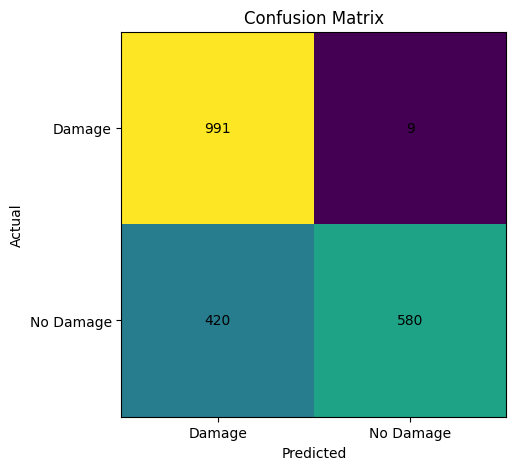

In [21]:
cm = confusion_matrix(
    true_labels,
    predictions
)

print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")

plt.xticks(
    [0, 1],
    ["Damage", "No Damage"]
)

plt.yticks(
    [0, 1],
    ["Damage", "No Damage"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.show()

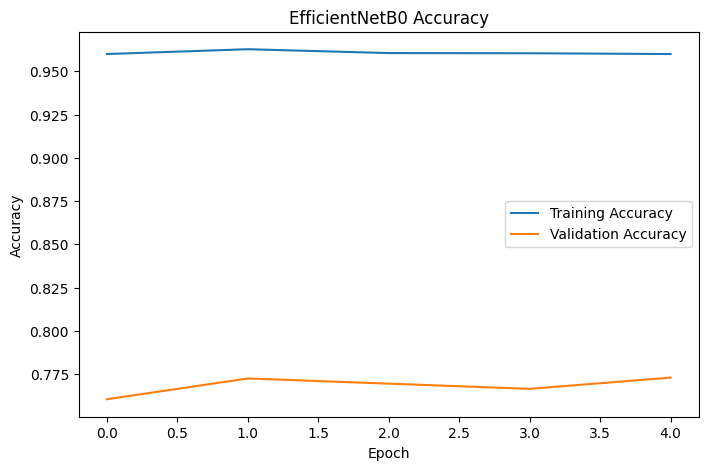

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "EfficientNetB0 Accuracy"
)

plt.legend()

plt.show()

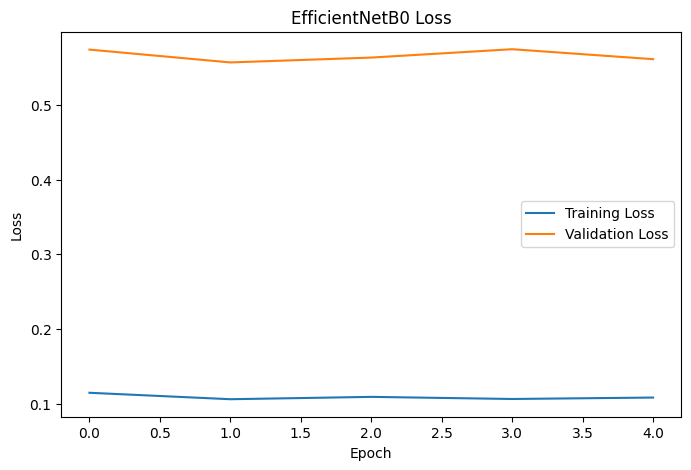

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "EfficientNetB0 Loss"
)

plt.legend()

plt.show()

In [24]:
from tensorflow.keras.utils import load_img, img_to_array

In [25]:
def predict_building(image_path):

    img = load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = img_to_array(img)

    input_image = np.expand_dims(
        img_array,
        axis=0
    )

    probability = model.predict(
        input_image,
        verbose=0
    )[0][0]

    if probability >= 0.5:

        prediction = "No Damage"

        confidence = probability * 100

    else:

        prediction = "Damage"

        confidence = (
            1 - probability
        ) * 100

    plt.figure(figsize=(6, 6))

    plt.imshow(img)

    plt.axis("off")

    plt.title(
        f"Prediction: {prediction}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.show()

    print("------------------------------")
    print("Prediction :", prediction)
    print(
        "Confidence :",
        f"{confidence:.2f}%"
    )
    print("------------------------------")

    return prediction, confidence

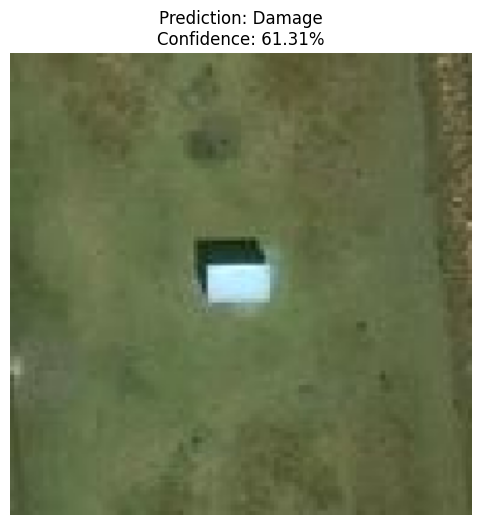

------------------------------
Prediction : Damage
Confidence : 61.31%
------------------------------


('Damage', np.float32(61.306156))

In [26]:
IMAGE_PATH = "/content/test/no_damage/-95.061894_30.007746.jpeg"

predict_building(
    IMAGE_PATH
)

In [27]:
model.save(
    "/content/working_pp"
    "building_damage_efficientnet.keras"
)

print("Model saved successfully.")

Model saved successfully.


In [31]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [34]:
TRAIN_DIR = "/content/train_another"
VAL_DIR   = "/content/validation_another"
TEST_DIR  = "/content/test"

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 2

In [35]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="binary",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 10000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.
Classes: ['damage', 'no_damage']


In [36]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [37]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

In [38]:
class OverlapPatchEmbedding(layers.Layer):

    def __init__(
        self,
        embed_dim,
        patch_size,
        stride
    ):
        super().__init__()

        self.projection = layers.Conv2D(
            filters=embed_dim,
            kernel_size=patch_size,
            strides=stride,
            padding="same"
        )

        self.norm = layers.LayerNormalization(
            epsilon=1e-6
        )

    def call(self, x):

        x = self.projection(x)

        shape = tf.shape(x)

        batch = shape[0]
        height = shape[1]
        width = shape[2]
        channels = shape[3]

        x = tf.reshape(
            x,
            [batch, height * width, channels]
        )

        x = self.norm(x)

        return x, height, width

In [39]:
class MixFFN(layers.Layer):

    def __init__(
        self,
        embed_dim,
        expansion=4,
        dropout=0.1
    ):
        super().__init__()

        hidden_dim = embed_dim * expansion

        self.dense1 = layers.Dense(
            hidden_dim,
            activation=tf.nn.gelu
        )

        self.dropout1 = layers.Dropout(
            dropout
        )

        self.dense2 = layers.Dense(
            embed_dim
        )

        self.dropout2 = layers.Dropout(
            dropout
        )

    def call(
        self,
        x,
        training=False
    ):

        x = self.dense1(x)

        x = self.dropout1(
            x,
            training=training
        )

        x = self.dense2(x)

        x = self.dropout2(
            x,
            training=training
        )

        return x

In [40]:
class SegFormerBlock(layers.Layer):

    def __init__(
        self,
        embed_dim,
        num_heads,
        dropout=0.1
    ):
        super().__init__()

        self.norm1 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads,
            dropout=dropout
        )

        self.norm2 = layers.LayerNormalization(
            epsilon=1e-6
        )

        self.mlp = MixFFN(
            embed_dim,
            dropout=dropout
        )

    def call(
        self,
        x,
        training=False
    ):

        attention_input = self.norm1(x)

        attention_output = self.attention(
            attention_input,
            attention_input,
            training=training
        )

        x = x + attention_output

        mlp_input = self.norm2(x)

        mlp_output = self.mlp(
            mlp_input,
            training=training
        )

        return x + mlp_output

In [41]:
def build_segformer_classifier():

    inputs = keras.Input(
        shape=(224, 224, 3)
    )

    x = augmentation(inputs)

    x = layers.Rescaling(
        1.0 / 255
    )(x)

    # -------------------------
    # Stage 1
    # -------------------------

    patch1 = OverlapPatchEmbedding(
        embed_dim=32,
        patch_size=7,
        stride=4
    )

    x, h, w = patch1(x)

    for _ in range(2):

        x = SegFormerBlock(
            embed_dim=32,
            num_heads=1
        )(x)

    x = layers.LayerNormalization()(x)

    x = layers.Reshape(
        (56, 56, 32)
    )(x)

    # -------------------------
    # Stage 2
    # -------------------------

    patch2 = OverlapPatchEmbedding(
        embed_dim=64,
        patch_size=3,
        stride=2
    )

    x, h, w = patch2(x)

    for _ in range(2):

        x = SegFormerBlock(
            embed_dim=64,
            num_heads=2
        )(x)

    x = layers.LayerNormalization()(x)

    x = layers.Reshape(
        (28, 28, 64)
    )(x)

    # -------------------------
    # Stage 3
    # -------------------------

    patch3 = OverlapPatchEmbedding(
        embed_dim=160,
        patch_size=3,
        stride=2
    )

    x, h, w = patch3(x)

    for _ in range(2):

        x = SegFormerBlock(
            embed_dim=160,
            num_heads=5
        )(x)

    x = layers.LayerNormalization()(x)

    x = layers.Reshape(
        (14, 14, 160)
    )(x)

    # -------------------------
    # Stage 4
    # -------------------------

    patch4 = OverlapPatchEmbedding(
        embed_dim=256,
        patch_size=3,
        stride=2
    )

    x, h, w = patch4(x)

    for _ in range(2):

        x = SegFormerBlock(
            embed_dim=256,
            num_heads=8
        )(x)

    # Classification head

    x = layers.LayerNormalization()(x)

    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(
        256,
        activation="gelu"
    )(x)

    x = layers.Dropout(0.4)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name="SegFormer_Classifier"
    )

In [42]:
segformer_model = build_segformer_classifier()

segformer_model.summary()

Model: "SegFormer_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ overlap_patch_embedding         │ [(None, 3136, 32), (), │         4,800 │
│ (OverlapPatchEmbedding)         │ ()]                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ seg_former_block                │ (None, 3136, 32)       │        12,704 │
│ (SegFormerBlock)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ seg_former_block_1              │ (None, 3136, 32)       │        12,704 │
│ (SegFormerBlock)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_5           │ (None, 3136, 32)       │            64 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ overlap_patch_embedding_1       │ [(None, 784, 64), (),  │        18,624 │
│ (OverlapPatchEmbedding)         │ ()]                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ seg_former_block_2              │ (None, 784, 64)        │        49,984 │
│ (SegFormerBlock)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ seg_former_block_3              │ (None, 784, 64)        │        49,984 │
│ (SegFormerBlock)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_11          │ (None, 784, 64)        │           128 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ overlap_patch_embedding_2       │ [(None, 196, 160), (), │        92,640 │
│ (OverlapPatchEmbedding)         │ ()]                    │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ seg_former_block_4              │ (None, 196, 160)       │       309,280 │
│ (SegFormerBlock)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ seg_former_block_5              │ (None, 196, 160)       │       309,280 │
│ (SegFormerBlock)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer_normalization_17          │ (None, 196, 160)       │           320 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 14, 14, 160)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ overlap_patch_embedding_3       │ [(None, 49, 256), (),  │       369,40

 Total params: 2,876,001 (10.97 MB)

 Trainable params: 2,876,001 (10.97 MB)

 Non-trainable params: 0 (0.00 B)

In [43]:
segformer_model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=1e-4,
        weight_decay=1e-4
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(
            name="precision"
        ),
        tf.keras.metrics.Recall(
            name="recall"
        ),
        tf.keras.metrics.AUC(
            name="auc"
        )
    ]
)

In [44]:
segformer_callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        "/content/working_pp/best_segformer.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [45]:
segformer_history = segformer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=segformer_callbacks
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 648ms/step - accuracy: 0.4988 - auc: 0.4945 - loss: 0.7499 - precision: 0.5013 - recall: 0.5017
Epoch 1: val_accuracy improved from None to 0.50000, saving model to /content/working_pp/best_segformer.keras

Epoch 1: finished saving model to /content/working_pp/best_segformer.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 260s 692ms/step - accuracy: 0.5008 - auc: 0.5027 - loss: 0.7167 - precision: 0.5008 - recall: 0.5118 - val_accuracy: 0.5000 - val_auc: 0.5837 - val_loss: 0.6949 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 628ms/step - accuracy: 0.4971 - auc: 0.4990 - loss: 0.7012 - precision: 0.5022 - recall: 0.4994
Epoch 2: val_accuracy did not improve from 0.50000
313/313 ━━━━━━━━━━━━━━━━━━━━ 208s 665ms/step - accuracy: 0.5004 - auc: 0.5041 - loss: 0.6997 - precision: 0.5004 - recall: 0.4970 - val_accuracy: 0.5000 - val_auc: 0.6031 - val_loss: 0.6951 - val_precision: 0.5000 

In [46]:
segformer_model.save(
    "/content/working_pp/segformer_damage_classifier.keras"
)

63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 187ms/step - accuracy: 0.9675 - auc: 0.9959 - loss: 0.0803 - precision: 0.9689 - recall: 0.9660

TEST MODEL RESULTS
loss: 0.0803
compile_metrics: 0.9675
63/63 ━━━━━━━━━━━━━━━━━━━━ 14s 189ms/step

FINAL TEST METRICS
Accuracy  : 96.75%
Precision : 96.89%
Recall    : 96.60%
F1 Score  : 96.75%
ROC-AUC   : 0.9963

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Class 0     0.9661    0.9690    0.9675      1000
     Class 1     0.9689    0.9660    0.9675      1000

    accuracy                         0.9675      2000
   macro avg     0.9675    0.9675    0.9675      2000
weighted avg     0.9675    0.9675    0.9675      2000


Confusion Matrix:
[[969  31]
 [ 34 966]]


<Figure size 700x600 with 0 Axes>

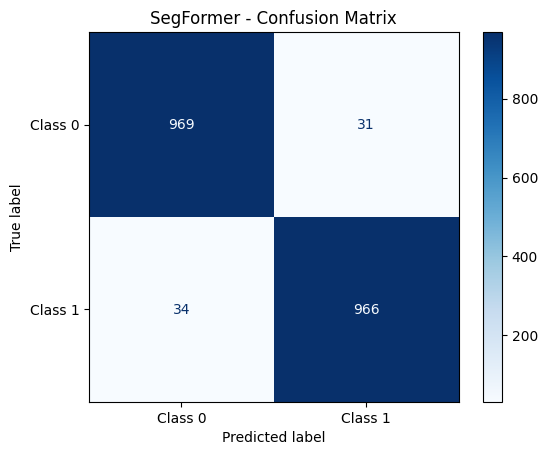

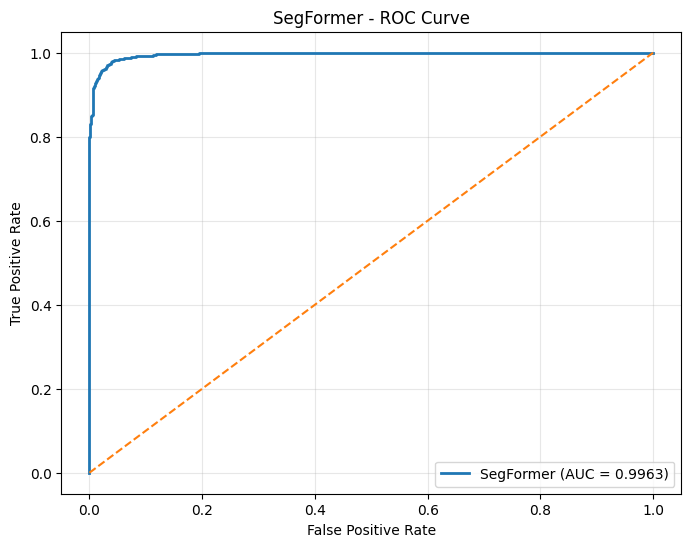

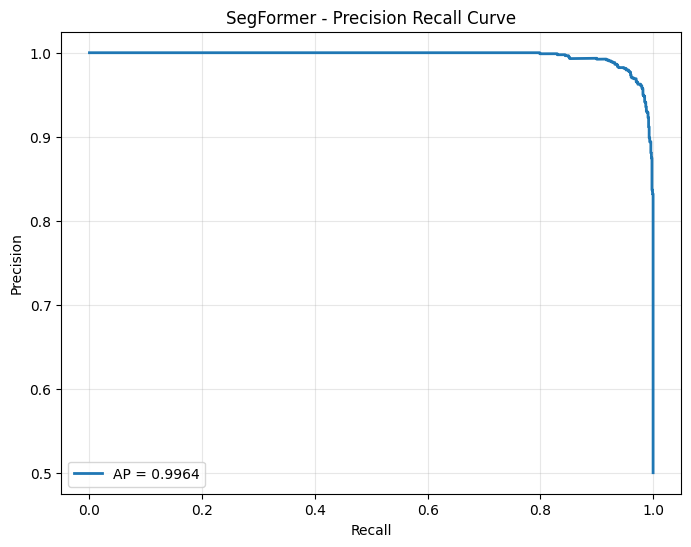

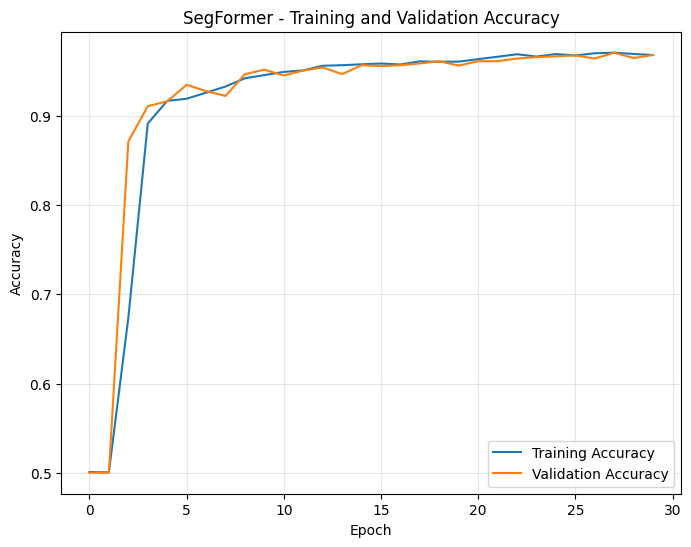

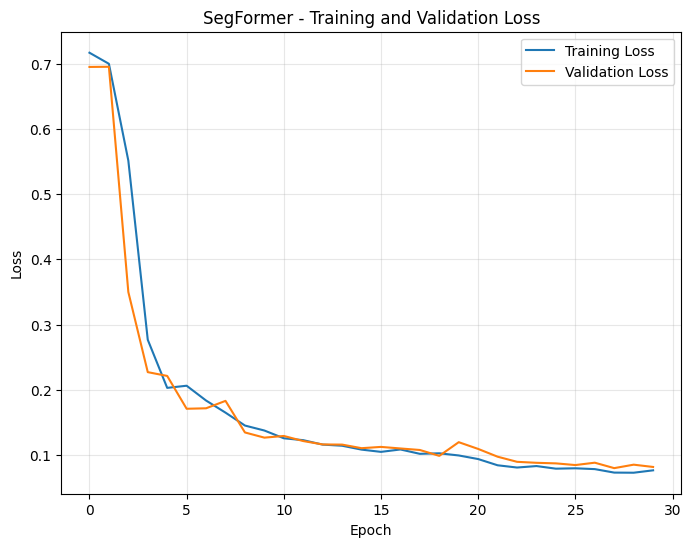

In [58]:
# ============================================================
# SEGFORMER MODEL EVALUATION
# Accuracy, Precision, Recall, F1, Classification Report,
# Confusion Matrix, ROC Curve, AUC, Precision-Recall Curve
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# 1. Evaluate model on TEST dataset
# ------------------------------------------------------------

test_results = segformer_model.evaluate(
    test_ds,
    verbose=1
)

print("\n==============================")
print("TEST MODEL RESULTS")
print("==============================")

for name, value in zip(segformer_model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")


# ------------------------------------------------------------
# 2. Get true labels and predictions
# ------------------------------------------------------------

y_true = np.concatenate([
    labels.numpy().reshape(-1)
    for images, labels in test_ds
])

y_prob = segformer_model.predict(
    test_ds,
    verbose=1
).reshape(-1)

y_pred = (y_prob >= 0.5).astype(int)


# ------------------------------------------------------------
# 3. Class names
# ------------------------------------------------------------

# From your dataset:
# Change these only if your folder/class names are different.

class_names = ["Class 0", "Class 1"]


# ------------------------------------------------------------
# 4. Accuracy, Precision, Recall, F1 Score
# ------------------------------------------------------------

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

auc_score = roc_auc_score(
    y_true,
    y_prob
)

print("\n==============================")
print("FINAL TEST METRICS")
print("==============================")

print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")
print(f"ROC-AUC   : {auc_score:.4f}")


# ------------------------------------------------------------
# 5. Classification Report
# ------------------------------------------------------------

print("\n==============================")
print("CLASSIFICATION REPORT")
print("==============================")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 6. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

plt.figure(figsize=(7, 6))
disp.plot(
    cmap="Blues",
    values_format="d"
)
plt.title("SegFormer - Confusion Matrix")
plt.show()


# ------------------------------------------------------------
# 7. ROC Curve
# ------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_prob
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"SegFormer (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SegFormer - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# 8. Precision-Recall Curve
# ------------------------------------------------------------

pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_true,
    y_prob
)

average_precision = average_precision_score(
    y_true,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    pr_recall,
    pr_precision,
    linewidth=2,
    label=f"AP = {average_precision:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("SegFormer - Precision Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# 9. Training Accuracy Graph
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    segformer_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    segformer_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SegFormer - Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ------------------------------------------------------------
# 10. Training Loss Graph
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    segformer_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    segformer_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("SegFormer - Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [55]:
!pip show tensorflow

Name: tensorflow
Version: 2.20.0
Summary: TensorFlow is an open source machine learning framework for everyone.
Home-page: https://www.tensorflow.org/
Author: Google Inc.
Author-email: packages@tensorflow.org
License: Apache 2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: absl-py, astunparse, flatbuffers, gast, google_pasta, grpcio, h5py, keras, libclang, ml_dtypes, numpy, opt_einsum, packaging, protobuf, requests, setuptools, six, tensorboard, termcolor, typing_extensions, wrapt
Required-by: dopamine_rl, tensorflow-text, tf_keras, ydf_tf


Swin Transformer TensorFlow